<a href="https://colab.research.google.com/github/SyedJunaidImran/heart-disease-ml-evaluation/blob/main/Disease_Prediction_Evaluation_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

--- Evaluation Metrics ---
Accuracy : 0.8033 (80.33%)
Precision: 0.7692 (76.92%)
Recall   : 0.9091 (90.91%)
F1-Score : 0.8333 (83.33%)

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.68      0.76        28
           1       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61



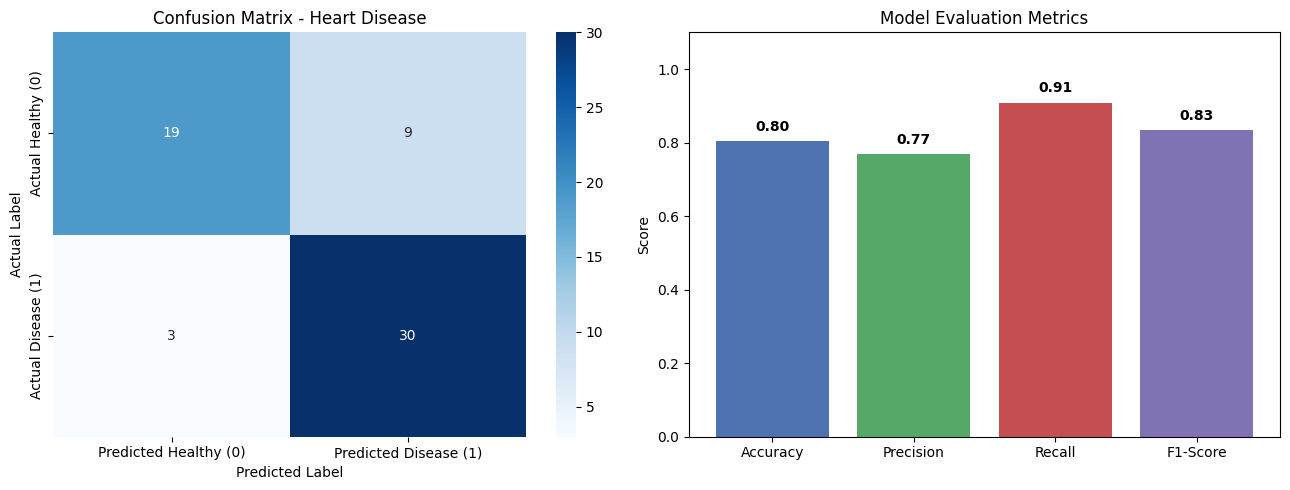

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Load Dataset
df = pd.read_csv('heart.csv')

# Drop unnamed index column if present in Kaggle's Heart.csv
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Dataset Shape:", df.shape)
display(df.head())

# 2. Data Pre-processing
print("\nMissing Values:\n", df.isnull().sum())

# Automatically detect the target column ('target' or 'AHD')
if 'target' in df.columns:
    target_col = 'target'
    y = df[target_col]
elif 'AHD' in df.columns:
    target_col = 'AHD'
    y = df[target_col].map({'Yes': 1, 'No': 0})
else:
    # Fallback to the last column if named differently
    target_col = df.columns[-1]
    y = pd.factorize(df[target_col])[0]

X = df.drop(columns=[target_col])

# One-hot encode categorical columns (like ChestPain, Thal)
X = pd.get_dummies(X, drop_first=True)

# Impute any missing numeric values with median
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

# 4. Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"\n--- Evaluation Metrics ---")
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall   : {rec:.4f} ({rec*100:.2f}%)")
print(f"F1-Score : {f1:.4f} ({f1*100:.2f}%)")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 5. Visualize Results
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Predicted Healthy (0)', 'Predicted Disease (1)'],
            yticklabels=['Actual Healthy (0)', 'Actual Disease (1)'])
axes[0].set_title('Confusion Matrix - Heart Disease')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [acc, prec, rec, f1]
bars = axes[1].bar(metrics_names, metrics_values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'])
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Model Evaluation Metrics')
axes[1].set_ylabel('Score')

for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('evaluation_results.png', dpi=300)
plt.show()
